# Automatidata: NYC Taxi Data (Visualization Stage)

Case study from the Google Advanced Data Analytics Professional Certificate. Building on the Plan/Analyze stage, this notebook explores trip distance, revenue, and tip patterns through EDA visualizations ahead of building an executive-facing story in Tableau and Python.

## Plan

### Outliers: how to identify and handle them

we can use the interquantile to identify the outliers or by using boxplot, or by simply using describe() and check for outliers.
If its a typo or it can ruin the models performance remove them, if not then keep them.

### Imports and data loading



In [1]:
# Import packages and libraries
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
# Load dataset into dataframe
df = pd.read_csv('2017_Yellow_Taxi_Trip_Data.csv')

## Analyze

### Data exploration and cleaning

Which columns are applicable, which can be eliminated, and how should missing data and outliers be handled?


If there is missing data I should probably ask for them if they can give us the missing parts of the data. We can look for them if we can find them. If possible fill them with the mean value. We can just drop them if its not many that will not ruin anything. If none of these options then u should probably mention it in the presentation or the next meeting.

In [3]:
df.size

408582

In [4]:
df.head()

,Unnamed: 0,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
0,24870114,2,03/25/2017 8:55:43 AM,03/25/2017 9:09:47 AM,6,3.34,1,N,100,231,1,13.0,0.0,0.5,2.76,0.0,0.3,16.56
1,35634249,1,04/11/2017 2:53:28 PM,04/11/2017 3:19:58 PM,1,1.80,1,N,186,43,1,16.0,0.0,0.5,4.00,0.0,0.3,20.80
2,106203690,1,12/15/2017 7:26:56 AM,12/15/2017 7:34:08 AM,1,1.00,1,N,262,236,1,6.5,0.0,0.5,1.45,0.0,0.3,8.75
3,38942136,2,05/07/2017 1:17:59 PM,05/07/2017 1:48:14 PM,1,3.70,1,N,188,97,1,20.5,0.0,0.5,6.39,0.0,0.3,27.69
4,30841670,2,04/15/2017 11:32:20 PM,04/15/2017 11:49:03 PM,1,4.37,1,N,4,112,2,16.5,0.5,0.5,0.00,0.0,0.3,17.80


Use describe... 

In [5]:
df.describe()

,Unnamed: 0,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
count,2.269900e+04,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000
mean,5.675849e+07,1.556236,1.642319,2.913313,1.043394,162.412353,161.527997,1.336887,13.026629,0.333275,0.497445,1.835781,0.312542,0.299551,16.310502
std,3.274493e+07,0.496838,1.285231,3.653171,0.708391,66.633373,70.139691,0.496211,13.243791,0.463097,0.039465,2.800626,1.399212,0.015673,16.097295
min,1.212700e+04,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,-120.000000,-1.000000,-0.500000,0.000000,0.000000,-0.300000,-120.300000
25%,2.852056e+07,1.000000,1.000000,0.990000,1.000000,114.000000,112.000000,1.000000,6.500000,0.000000,0.500000,0.000000,0.000000,0.300000,8.750000
50%,5.673150e+07,2.000000,1.000000,1.610000,1.000000,162.000000,162.000000,1.000000,9.500000,0.000000,0.500000,1.350000,0.000000,0.300000,11.800000
75%,8.537452e+07,2.000000,2.000000,3.060000,1.000000,233.000000,233.000000,2.000000,14.500000,0.500000,0.500000,2.450000,0.000000,0.300000,17.800000
max,1.134863e+08,2.000000,6.000000,33.960000,99.000000,265.000000,265.000000,4.000000,999.990000,4.500000,0.500000,200.000000,19.100000,0.300000,1200.290000


And info. 

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22699 entries, 0 to 22698
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             22699 non-null  int64  
 1   VendorID               22699 non-null  int64  
 2   tpep_pickup_datetime   22699 non-null  object 
 3   tpep_dropoff_datetime  22699 non-null  object 
 4   passenger_count        22699 non-null  int64  
 5   trip_distance          22699 non-null  float64
 6   RatecodeID             22699 non-null  int64  
 7   store_and_fwd_flag     22699 non-null  object 
 8   PULocationID           22699 non-null  int64  
 9   DOLocationID           22699 non-null  int64  
 10  payment_type           22699 non-null  int64  
 11  fare_amount            22699 non-null  float64
 12  extra                  22699 non-null  float64
 13  mta_tax                22699 non-null  float64
 14  tip_amount             22699 non-null  float64
 15  to

### Task 2b. Assess whether dimensions and measures are correct

On the data source page in Tableau, double check the data types for the applicable columns you selected on the previous step. Pay close attention to the dimensions and measures to assure they are correct. 

In Python, consider the data types of the columns. *Consider:* Do they make sense? 

Review the link provided in the previous activity instructions to create the required Tableau visualization. 

### Select visualization types

Which chart types make the most sense for EDA on this dataset?

Bar chart, box plot, histogram, and scatter plot.

## Construct


### Boxplots and distributions

Check for outliers on relevant columns, starting with trip distance and trip duration.



In [7]:
# Convert data columns to datetime
df["tpep_pickup_datetime"] = pd.to_datetime(df["tpep_pickup_datetime"])
df["tpep_dropoff_datetime"] = pd.to_datetime(df["tpep_dropoff_datetime"])

**trip distance**

Text(0.5, 1.0, 'Trip distance')

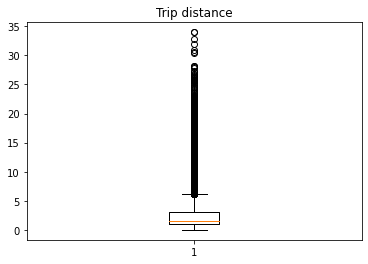

In [8]:
# Create box plot of trip_distance
plt.boxplot(df["trip_distance"]);
plt.title("Trip distance")

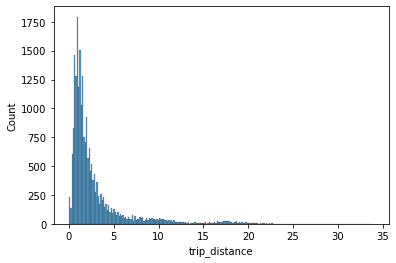

In [9]:
# Create histogram of trip_distance
sns.histplot(df["trip_distance"])

**total amount**

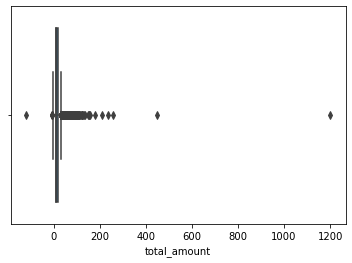

In [10]:
# Create box plot of total_amount
sns.boxplot(df["total_amount"])

Text(0, 0.5, 'Count')

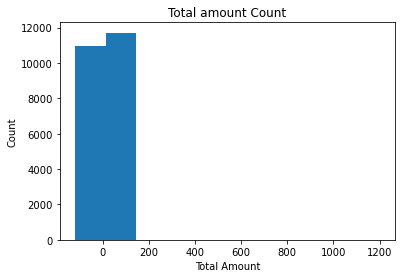

In [11]:
# Create histogram of total_amount
plt.hist(df["total_amount"]);
plt.title("Total amount Count")
plt.xlabel("Total Amount")
plt.ylabel("Count")

**tip amount**

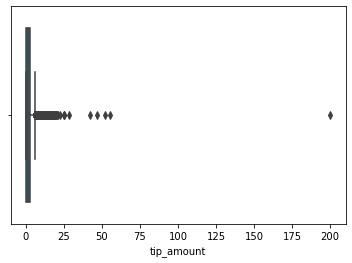

In [12]:
# Create box plot of tip_amount
sns.boxplot(df["tip_amount"])

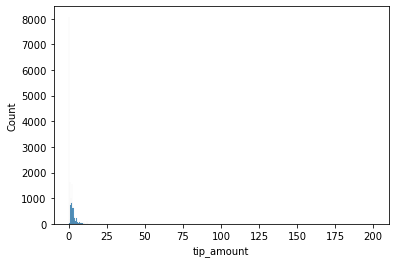

In [13]:
# Create histogram of tip_amount
sns.histplot(df["tip_amount"])
# tip_amount max is 200

**tip_amount by vendor**

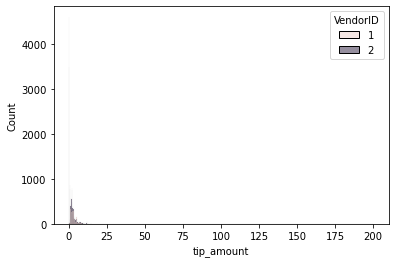

In [14]:
# Create histogram of tip_amount by vendor
sns.histplot(x = df["tip_amount"], hue=df["VendorID"])

Next, zoom in on the upper end of the range of tips to check whether vendor one gets noticeably more of the most generous tips.

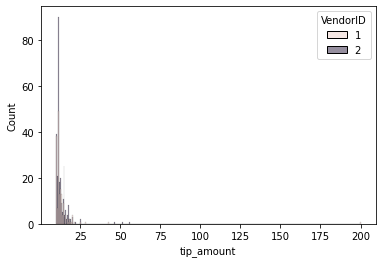

In [15]:
# Create histogram of tip_amount by vendor for tips > $10 
x1 = df[df["tip_amount"] > 10]
sns.histplot(x = x1["tip_amount"], hue=x1["VendorID"]) # we can use multiple="dodge" to see the results better too

**Mean tips by passenger count**

In [16]:
df["passenger_count"].value_counts()

1    16117
2     3305
5     1143
3      953
6      693
4      455
0       33
Name: passenger_count, dtype: int64

In [17]:
# Calculate mean tips by passenger_count
df.groupby("passenger_count")["tip_amount"].mean()

passenger_count
0    2.135758
1    1.848920
2    1.856378
3    1.716768
4    1.530264
5    1.873185
6    1.720260
Name: tip_amount, dtype: float64

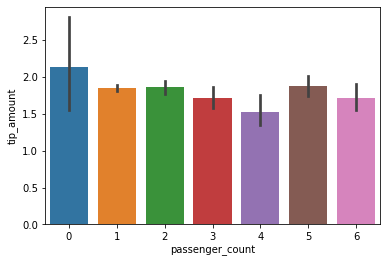

In [18]:
# Create bar plot for mean tips by passenger count
sns.barplot(x=df["passenger_count"], y=df["tip_amount"]) #by default its the mean

**Create month and day columns**

In [19]:
# Create a month column
df["month"] = df["tpep_pickup_datetime"].dt.month
df["month_name"] = df["tpep_pickup_datetime"].dt.month_name()

# Create a day column
df["day"] = df["tpep_pickup_datetime"].dt.day
df

,Unnamed: 0,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,...,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,month,month_name,day
0,24870114,2,2017-03-25 08:55:43,2017-03-25 09:09:47,6,3.34,1,N,100,231,...,13.0,0.0,0.5,2.76,0.00,0.3,16.56,3,March,25
1,35634249,1,2017-04-11 14:53:28,2017-04-11 15:19:58,1,1.80,1,N,186,43,...,16.0,0.0,0.5,4.00,0.00,0.3,20.80,4,April,11
2,106203690,1,2017-12-15 07:26:56,2017-12-15 07:34:08,1,1.00,1,N,262,236,...,6.5,0.0,0.5,1.45,0.00,0.3,8.75,12,December,15
3,38942136,2,2017-05-07 13:17:59,2017-05-07 13:48:14,1,3.70,1,N,188,97,...,20.5,0.0,0.5,6.39,0.00,0.3,27.69,5,May,7
4,30841670,2,2017-04-15 23:32:20,2017-04-15 23:49:03,1,4.37,1,N,4,112,...,16.5,0.5,0.5,0.00,0.00,0.3,17.80,4,April,15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22694,14873857,2,2017-02-24 17:37:23,2017-02-24 17:40:39,3,0.61,1,N,48,186,...,4.0,1.0,0.5,0.00,0.00,0.3,5.80,2,February,24
22695,66632549,2,2017-08-06 16:43:59,2017-08-06 17:24:47,1,16.71,2,N,132,164,...,52.0,0.0,0.5,14.64,5.76,0.3,73.20,8,August,6
22696,74239933,2,2017-09-04 14:54:14,2017-09-04 14:58:22,1,0.42,1,N,107,234,...,4.5,0.0,0.5,0.00,0.00,0.3,5.30,9,September,4
22697,60217333,2,2017-07-15 12:56:30,2017-07-15 13:08:26,1,2.36,1,N,68,144,...,10.5,0.0,0.5,1.70,0.00,0.3,13.00,7,July,15


**Total ride count by month**

In [20]:
# Get total number of rides for each month
x = df["month"].value_counts()

In [21]:
# Reorder the monthly ride list so months go in order
x = x.sort_index()

In [22]:
# Show the index
x.index

Int64Index([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12], dtype='int64')

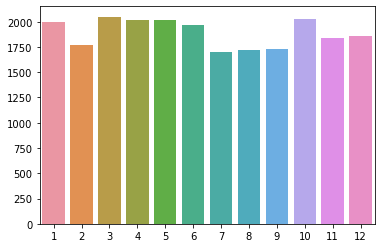

In [23]:
# Create a bar plot of total rides per month
sns.barplot(x =x.index,y=x.values) # we can also do it by sing the month name it will be more clearer
 

**Total ride count by day**

In [24]:
# Repeat the above process, this time for rides by day
daycount = df["day"].value_counts().sort_index()
daycount

1     721
2     739
3     810
4     703
5     746
6     718
7     788
8     752
9     714
10    760
11    788
12    791
13    782
14    742
15    761
16    759
17    795
18    806
19    784
20    727
21    788
22    735
23    663
24    703
25    708
26    695
27    732
28    763
29    649
30    669
31    408
Name: day, dtype: int64

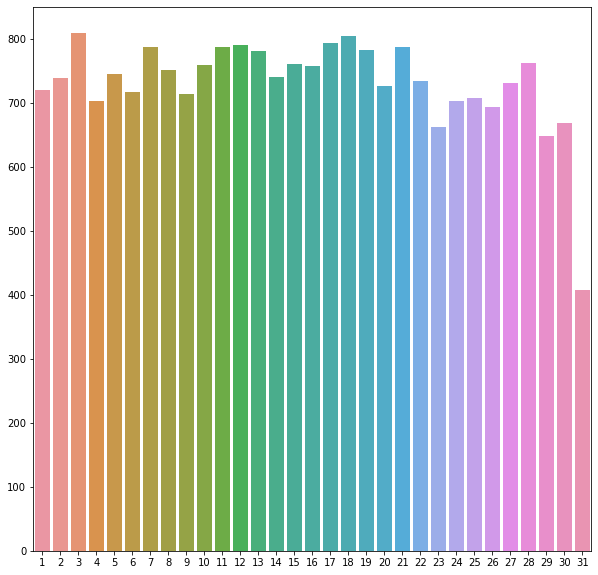

In [25]:
# Create bar plot for ride count by day
plt.figure(figsize=(10,10))
sns.barplot(x=daycount.index, y = daycount.values)


**Total revenue by day of the week**

In [26]:
# Repeat the process, this time for total revenue by day
df["day_name"] = df["tpep_pickup_datetime"].dt.day_name()
days = ["Saturday","Sunday", "Monday","Tuesday","Wednesday","Thursday","Friday"]
rev_by_day = df.groupby("day_name")["total_amount"].sum().reindex(days).reset_index()
rev_by_day.columns = ["day_name", "total_revenue"]
rev_by_day

,day_name,total_revenue
0,Saturday,51195.40
1,Sunday,48624.06
2,Monday,49574.37
3,Tuesday,52527.14
4,Wednesday,55310.47
5,Thursday,57181.91
6,Friday,55818.74


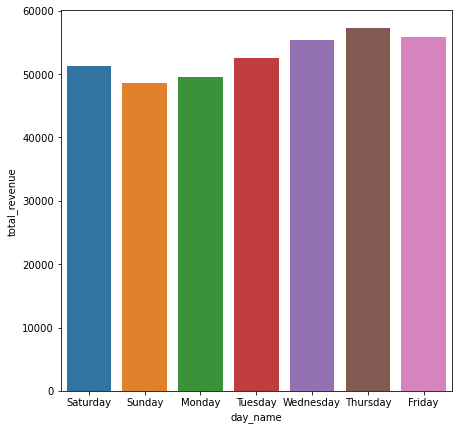

In [27]:
# Create bar plot of total revenue by day
plt.figure(figsize=(7,7))
sns.barplot(x=rev_by_day["day_name"], y=rev_by_day["total_revenue"])

**Total revenue by month**

In [40]:
# Repeat the process, this time for total revenue by month
df["month_name"] = df["tpep_pickup_datetime"].dt.month_name()
months = ["January","February","March","April","May","June","July","August","September","October","November","December"]
month_rev = df.groupby("month_name")["total_amount"].sum().reindex(months).reset_index()
month_rev

,month_name,total_amount
0,January,31735.25
1,February,28937.89
2,March,33085.89
3,April,32012.54
4,May,33828.58
5,June,32920.52
6,July,26617.64
7,August,27759.56
8,September,28206.38
9,October,33065.83


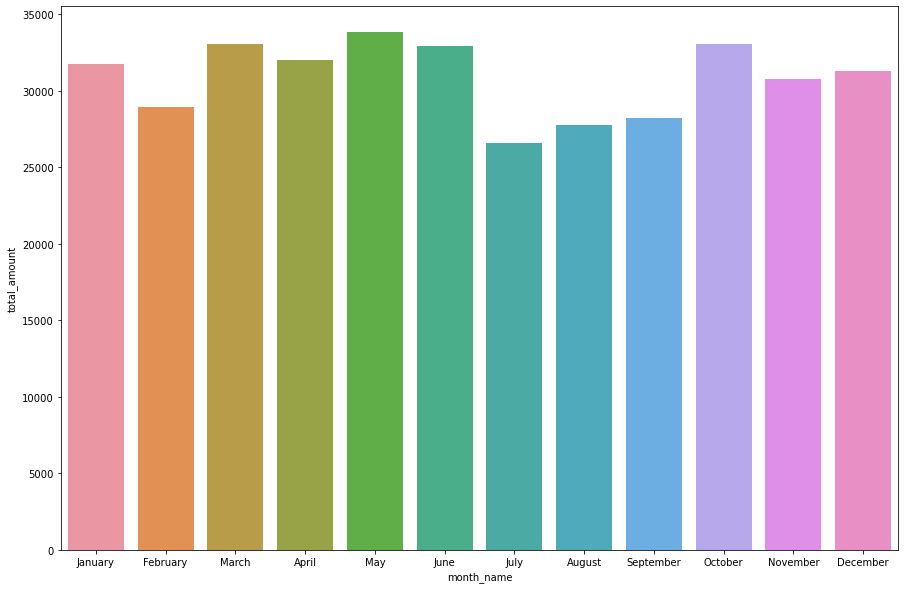

In [46]:
# Create a bar plot of total revenue by month
plt.figure(figsize = (15,10))
sns.barplot(x=month_rev["month_name"],y=  month_rev["total_amount"])

#### Scatter plot

**Mean trip distance by drop-off location**

In [49]:
# Get number of unique drop-off location IDs
df["DOLocationID"].nunique()

216

In [58]:
# Calculate the mean trip distance for each drop-off location
dotrip = df.groupby("DOLocationID")["trip_distance"].mean().reset_index()

# Sort the results in descending order by mean trip distance
dotrip = dotrip.sort_values(by ="trip_distance" , ascending = False)

,DOLocationID,trip_distance
16,23,24.275000
21,29,21.650000
167,210,20.500000
5,11,17.945000
40,51,17.310000
...,...,...
109,137,1.818852
189,234,1.727806
192,237,1.555494
154,193,1.390556


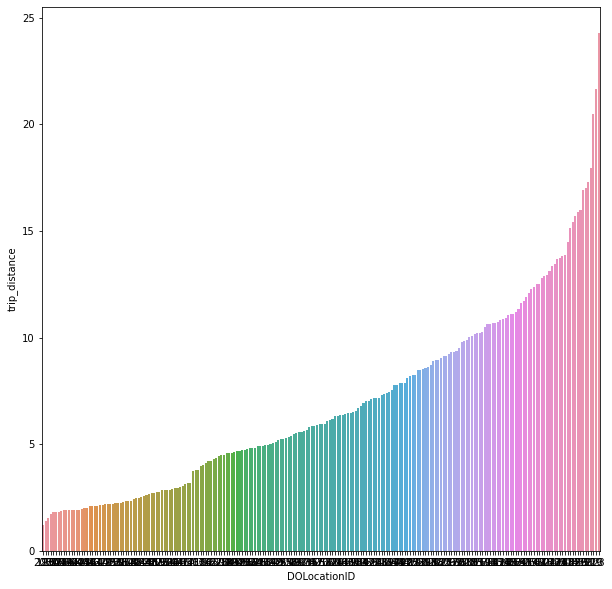

In [64]:
# Create a bar plot of mean trip distances by drop-off location in ascending order by distance
plt.figure(figsize = (10,10))
dotrip = dotrip.sort_values(by="trip_distance", ascending= True)
sns.barplot(x= dotrip["DOLocationID"], y = dotrip["trip_distance"], order = dotrip.DOLocationID )

**Bonus: confirming the pattern isn't just random noise**

To sanity-check the drop-off location pattern above, simulate 1,500 random point pairs from a normal distribution, compute pairwise distances, and see whether a similar-looking pattern emerges from pure randomness.

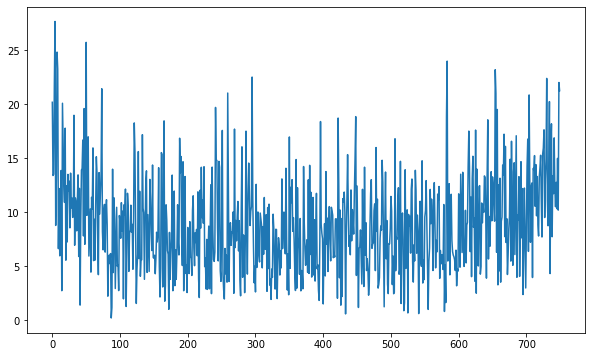

In [66]:
#BONUS CONTENT

#1. Generate random points on a 2D plane from a normal distribution
x = np.random.normal(10, 5, 1500)
y = np.random.normal(10, 5, 1500)

# 2. Calculate Euclidean distances between points in first half and second half of array
half = len(x) // 2
distances = np.sqrt((x[:half] - x[half:])**2 + (y[:half] - y[half:])**2)

# 3. Group the coordinates by "drop-off location", compute mean distance
coords = pd.DataFrame({"endpoint": list(zip(x[half:], y[half:])),"distance": distances})
mean_dist = coords.groupby("endpoint")["distance"].mean().reset_index()

# 4. Plot the mean distance between each endpoint ("drop-off location") and all points it connected to
plt.figure(figsize=(10, 6))
plt.plot(mean_dist["distance"].values)

**Histogram of rides by drop-off location**

First, check to whether the drop-off locations IDs are consecutively numbered. For instance, does it go 1, 2, 3, 4..., or are some numbers missing (e.g., 1, 3, 4...). If numbers aren't all consecutive, the histogram will look like some locations have very few or no rides when in reality there's no bar because there's no location. 

In [69]:
# Check if all drop-off locations are consecutively numbered
doloc = np.arange(df["DOLocationID"].min(), df["DOLocationID"].max() + 1)
np.array_equal(np.sort(df["DOLocationID"].unique()),doloc)

False

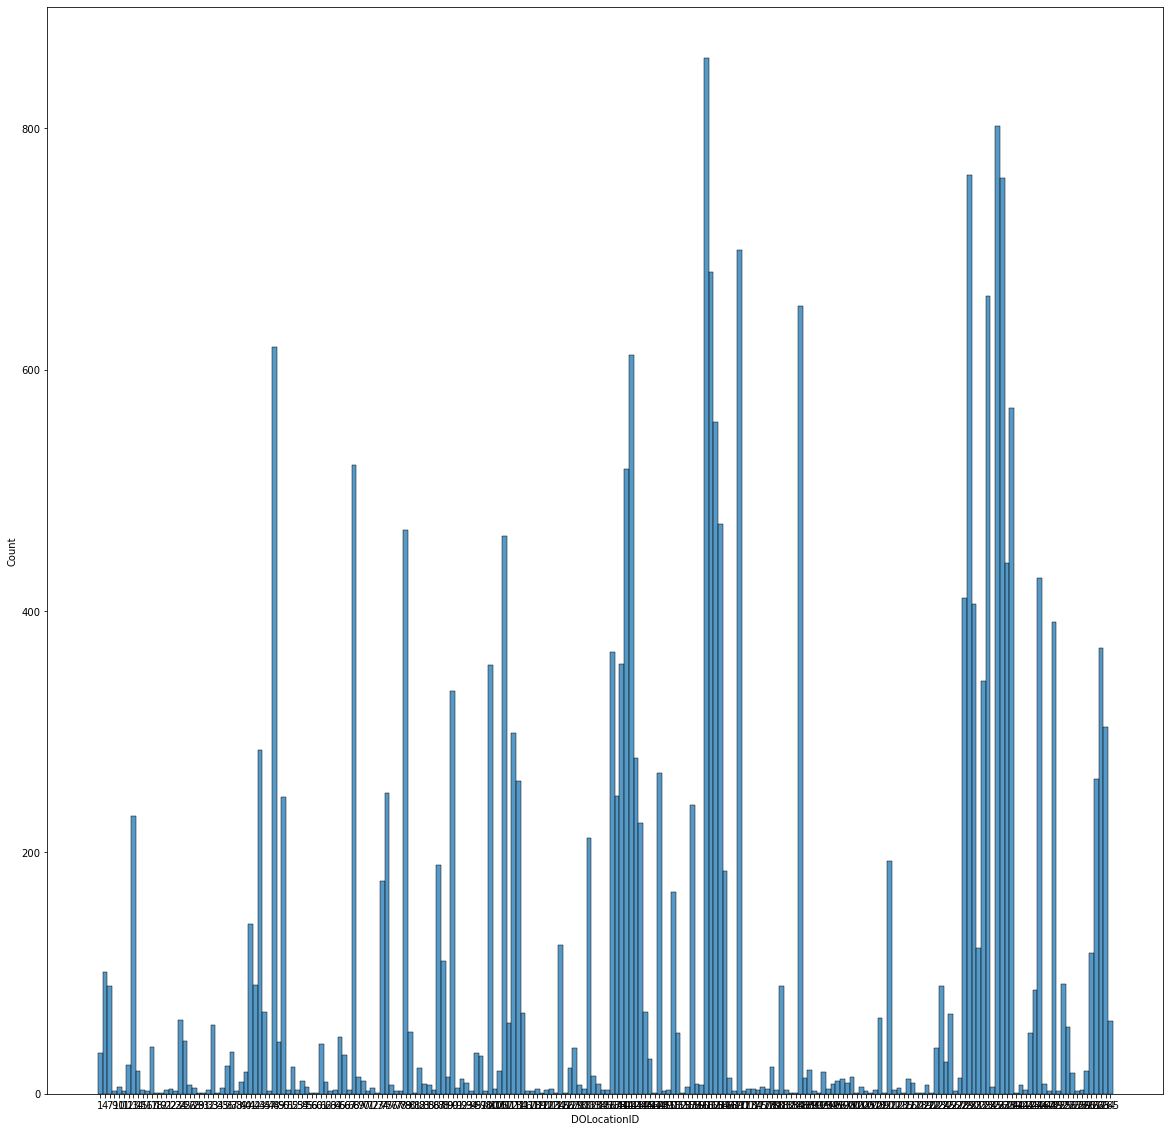

In [89]:
dfcopy = df.copy()
# DOLocationID column is numeric, so sort in ascending order
dfcopy = dfcopy.sort_values(by="DOLocationID", ascending=True)

# Convert to string
dfcopy["DOLocationID"] = dfcopy["DOLocationID"].astype(str)

# Plot
plt.figure(figsize=(20,20))
sns.histplot(x=dfcopy["DOLocationID"])

## Execute


### Results and evaluation

What did the visualizations reveal about the dataset, and what further questions did they raise?


Learned that trip distance and revenue vary a lots by drop off location and time some patterns come from real geography, others just from small sample sizes.
why do certain locations have oddly high low averages real effect or noise? Do outliers reflect data errors or real long trips?
Client would want which days/months bring the most revenue, and which locations to prioritize for driver allocation.

### Conclusion




EDA is important because you can know the relations between columns and know the datatypes


Visualizations helped me understand distribution and outliers at a glance patterns that would be hard to spot just scrolling through raw numbers.
